# Meeting: the chessboard

**Topic: representation.** The model stays the same, plain `LogisticRegression()`; **you may only
change the columns** you give it. Goal: **above 95%** on the test points.

1. 🧩 The chessboard.
2. 🧩 For those who finish: the dartboard.
3. 🧩 A riddle about pizza.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def plot_boundary(model, X, y, features, title=""):
    # colour the plane by the model's probability, and draw the 0.5 boundary;
    # features: the function that turns points (x1, x2) into the model's columns
    pad = 0.3
    g1, g2 = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    probs = model.predict_proba(features(np.c_[g1.ravel(), g2.ravel()]))[:, 1].reshape(g1.shape)
    plt.contourf(g1, g2, probs, levels=20, cmap="coolwarm", alpha=0.6)
    plt.contour(g1, g2, probs, levels=[0.5], colors="k", linewidths=1.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=12)
    plt.gca().set_aspect("equal"); plt.title(title); plt.show()

## 🧩 Challenge 1: the chessboard

Points on a $4 \times 4$ chessboard, coloured by the colour of their square. Find **new columns** so
that `LogisticRegression()` gets **above 95%** on the test points.

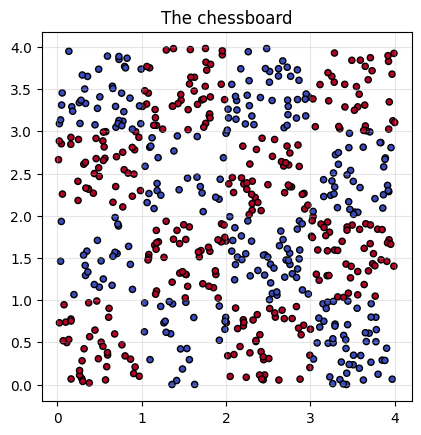

plain logistic regression, test accuracy: 0.6


In [2]:
rng = np.random.default_rng(0)
Xb = rng.uniform(0, 4, size=(600, 2))
yb = ((np.floor(Xb[:, 0]) + np.floor(Xb[:, 1])) % 2 == 0).astype(int)     # the colour of the square
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)

plt.scatter(Xb[:, 0], Xb[:, 1], c=yb, cmap="coolwarm", edgecolor="k", s=20)
plt.gca().set_aspect("equal"); plt.title("The chessboard"); plt.show()
print("plain logistic regression, test accuracy:", LogisticRegression().fit(Xb_tr, yb_tr).score(Xb_te, yb_te))

test accuracy: 1.0
[5.63264767 5.78663905]


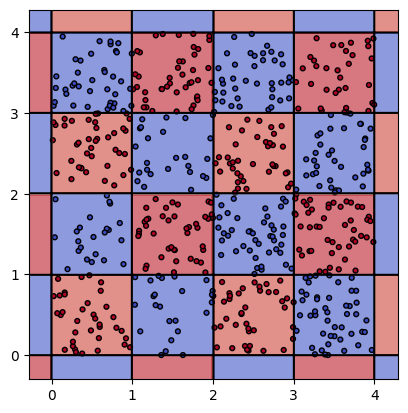

In [48]:
# 🧩 Your turn: build new columns from Xb_tr and Xb_te, then fit and score.

def weird(x):
    return np.exp(
        -np.pow(
            (1.41396*np.sin((np.pi/2)*(x - 0.5))),
            1000
        )
    )

def features(X):
    x = X[:, 0]
    y = X[:, 1]
    return np.array([
        weird(x)*weird(y),
        weird(x + 1)*weird(y + 1)
    ]).T

clf = LogisticRegression(max_iter=10000).fit(features(Xb_tr), yb_tr)
print("test accuracy:", clf.score(features(Xb_te), yb_te))
print(clf.coef_[0])
plot_boundary(clf, Xb, yb, features)

### ✅ Solution

*Together in class, after you try.*

## 🧩 Challenge 2: the dartboard

Done? A chessboard in **other coordinates**: rings of width 1 around the centre, and 6 slices of
$60^\circ$, coloured alternately. Again: **above 95%** with plain `LogisticRegression()`.

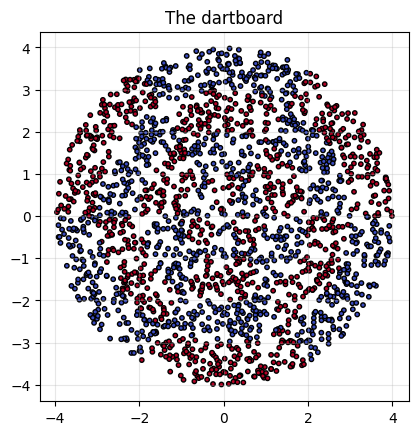

plain logistic regression, test accuracy: 0.5283333333333333


In [49]:
rng = np.random.default_rng(1)
Xd = rng.uniform(-4, 4, size=(4000, 2))
Xd = Xd[np.hypot(Xd[:, 0], Xd[:, 1]) < 4][:2000]
ring = np.floor(np.hypot(Xd[:, 0], Xd[:, 1]))
slice_ = np.floor((np.arctan2(Xd[:, 1], Xd[:, 0]) + np.pi) / (np.pi / 3))
yd = ((ring + slice_) % 2 == 0).astype(int)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=0, stratify=yd)

plt.scatter(Xd[:, 0], Xd[:, 1], c=yd, cmap="coolwarm", edgecolor="k", s=10)
plt.gca().set_aspect("equal"); plt.title("The dartboard"); plt.show()
print("plain logistic regression, test accuracy:", LogisticRegression().fit(Xd_tr, yd_tr).score(Xd_te, yd_te))

test accuracy: 1.0
[7.30160582 7.87447819]


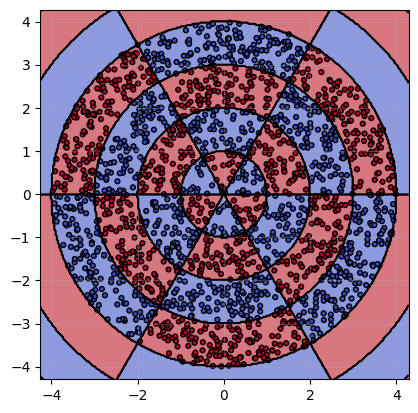

In [66]:
# 🧩 Your turn

def features(X):
    x = X[:, 0]
    y = X[:, 1]
    return np.array([
        weird(((x**2 + y**2)**0.5))*weird((3/np.pi)*(np.atan2(y, x) + np.pi)),
        weird(((x**2 + y**2)**0.5) + 1)*weird((3/np.pi)*(np.atan2(y, x) + np.pi) + 1)
    ]).T

clf = LogisticRegression(max_iter=10000).fit(features(Xd_tr), yd_tr)
print("test accuracy:", clf.score(features(Xd_te), yd_te))
print(clf.coef_[0])
plot_boundary(clf, Xd, yd, features)

### ✅ Solution

*Together in class, after you try.*

## 🧩 Challenge 3: a riddle about pizza

A pizza: no rings, just the 6 slices, coloured alternately. Surprise: **plain polynomial features of
degree 3**, with nothing else, solve it (almost) perfectly. Check it, and then explain **why**. Which
degree-3 polynomial in $x_1, x_2$ is positive exactly on every other slice?

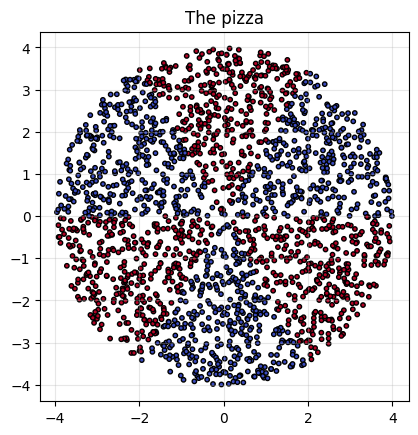

In [67]:
yp = (slice_ % 2 == 0).astype(int)
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xd, yp, test_size=0.3, random_state=0, stratify=yp)
plt.scatter(Xd[:, 0], Xd[:, 1], c=yp, cmap="coolwarm", edgecolor="k", s=10)
plt.gca().set_aspect("equal"); plt.title("The pizza"); plt.show()

# 🧩 Your turn: degree-3 polynomial features, then: why?

### ✅ Solution

*Together in class, after you try.*